# Breast Cancer Detection with XGBoost
Based on: Singh, Ansari & Jha (2026), *Cloud based Breast Cancer Detection using Machine Learning by XGBoost Method*, IJSRAIML 2(3), 179-196.

**Steps:** load data → explore → train XGBoost → evaluate → explain → **predict on your own input**.

> Educational demo only. Not a medical device.

In [ ]:
# !pip install xgboost scikit-learn pandas matplotlib seaborn ipywidgets
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay)
from xgboost import XGBClassifier
import ipywidgets as w
from IPython.display import display, clear_output

## 1. Load data
Wisconsin Diagnostic Breast Cancer dataset (built into scikit-learn). We use the 10 *mean* tumour measurements so the input form stays simple. Target: **1 = malignant, 0 = benign**.

In [ ]:
data = load_breast_cancer(as_frame=True)
X = data.data.filter(like="mean")
y = (data.target == 0).astype(int)
print(X.shape, "| malignant:", y.sum(), "| benign:", (y==0).sum())
X.head()

(569, 10) | malignant: 212 | benign: 357


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883


## 2. Explore

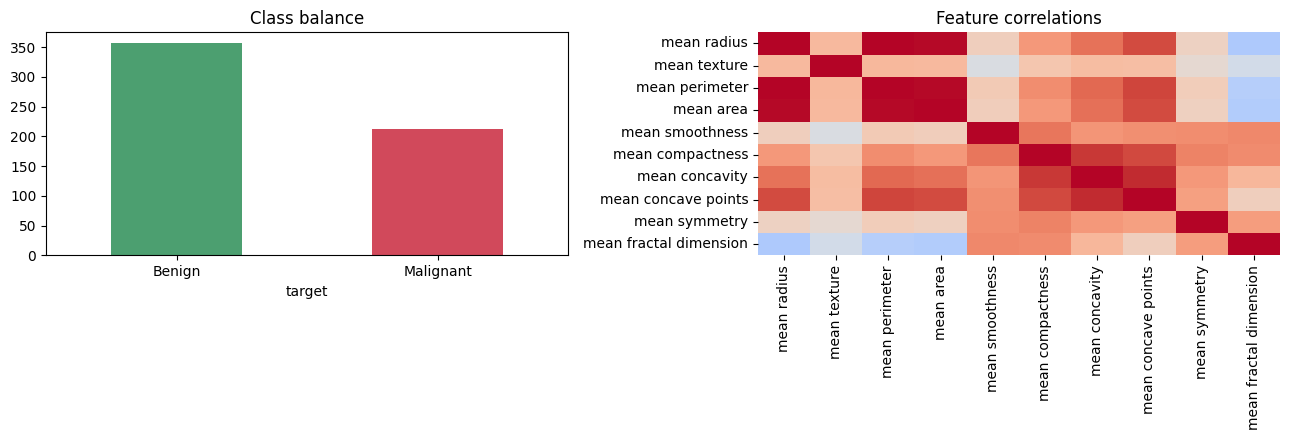

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
y.map({0:"Benign",1:"Malignant"}).value_counts().plot.bar(ax=ax[0], color=["#4C9F70","#D1495B"], rot=0)
ax[0].set_title("Class balance")
sns.heatmap(X.corr(), cmap="coolwarm", center=0, ax=ax[1], cbar=False); ax[1].set_title("Feature correlations")
plt.tight_layout(); plt.show()

## 3. Train XGBoost

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
model = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                      subsample=0.9, colsample_bytree=0.9, eval_metric="logloss", random_state=42)
model.fit(X_tr, y_tr)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.9, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

## 4. Evaluate

Accuracy              0.956
Precision             0.951
Recall                0.929
F1                    0.940
ROC-AUC               0.976
5-fold CV accuracy    0.946
dtype: float64


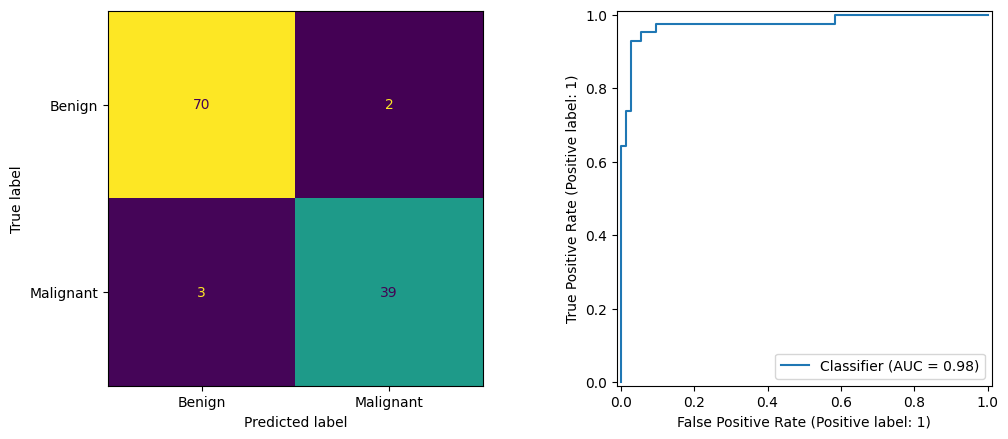

In [ ]:
pred, proba = model.predict(X_te), model.predict_proba(X_te)[:, 1]
print(pd.Series({
    "Accuracy": accuracy_score(y_te, pred), "Precision": precision_score(y_te, pred),
    "Recall": recall_score(y_te, pred), "F1": f1_score(y_te, pred), "ROC-AUC": roc_auc_score(y_te, proba),
    "5-fold CV accuracy": cross_val_score(model, X, y, cv=5).mean()}).round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Benign","Malignant"]).plot(ax=ax[0], colorbar=False)
RocCurveDisplay.from_predictions(y_te, proba, ax=ax[1]); plt.tight_layout(); plt.show()

## 5. Feature importance

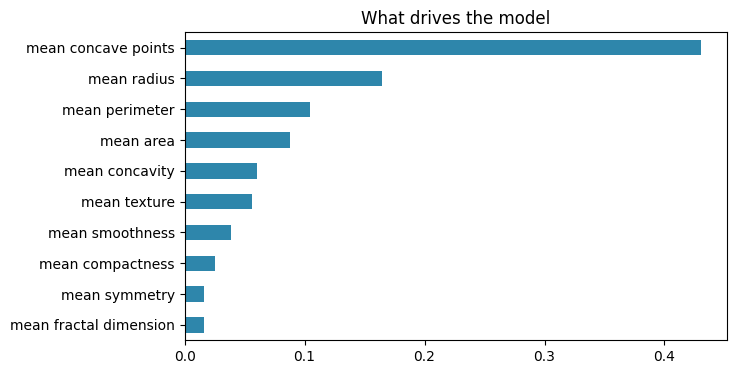

In [ ]:
pd.Series(model.feature_importances_, index=X.columns).sort_values().plot.barh(figsize=(7,4), color="#2E86AB")
plt.title("What drives the model"); plt.show()

## 6. Try it: enter your own input
Move the sliders and click **Predict**. (Defaults are the dataset averages.)

In [ ]:
sliders = {c: w.FloatSlider(value=float(X[c].mean()), min=float(X[c].min()), max=float(X[c].max()),
           step=float(X[c].max()-X[c].min())/200, description=c, readout_format=".3f",
           style={"description_width":"190px"}, layout=w.Layout(width="520px")) for c in X}
btn, out = w.Button(description="Predict", button_style="primary"), w.Output()

def predict_one(values: dict):
    p = float(model.predict_proba(pd.DataFrame([values])[X.columns])[0, 1])
    return ("Malignant" if p >= 0.5 else "Benign"), p

def on_click(_):
    with out:
        clear_output()
        label, p = predict_one({c: s.value for c, s in sliders.items()})
        print(f"Prediction: {label}   |   Malignancy probability: {p:.1%}")

btn.on_click(on_click)
display(w.VBox(list(sliders.values()) + [btn, out]))

In [ ]:
my_input = X.mean().round(3).to_dict()     # <- change values here
my_input["mean radius"], my_input["mean concavity"] = 20.0, 0.2
label, p = predict_one(my_input)
print(f"Prediction: {label}  |  Malignancy probability: {p:.1%}")

Prediction: Malignant  |  Malignancy probability: 76.1%


In [ ]:
# Batch prediction: CSV must contain the 10 mean-feature columns
# df = pd.read_csv("patients.csv")
# df["malignancy_probability"] = model.predict_proba(df[X.columns])[:, 1]
# df["prediction"] = np.where(df["malignancy_probability"] >= .5, "Malignant", "Benign"); df